# The midterms against earlier elections

This notebook puts the 3 November 2026 midterms next to the elections the study was trained on, November 2023 to
September 2026, on Kalshi and Polymarket separately. It reads the same price table as the two fit notebooks and the
midterm test, and changes none of them.

The midterm sample is exactly the pre-registered test's sample: every general-election contest of 3 November that
passed the selection and price rules, priced at 22:00 UTC, without Georgia, Louisiana and Mississippi. It is set by the
test's own code, so the two can't drift apart. The notebook works out by itself whether the preliminary or the final
run is the latest one and labels its figures and tables to match.

**The stretch** is the single number the study fits to a group of contests. At 1, prices were right on average. Above 1,
favourites won more often than their prices said (the market was underconfident). Below 1, they won less often
(overconfident). It is defined in `stretch.py`.

Five comparisons follow:
1. the stretch of each group, with its 95% interval;
2. how often favourites won at each price level;
3. every earlier election day, one at a time;
4. whether the stretch learnt from earlier elections would have improved the midterm prices;
5. the same midterm races on both platforms.

Tables go to `results/`, figures to `figures/`, all named `midterm_comparison_<stage>_...`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import PercentFormatter

import midterm_test
import stretch

PLATFORMS = ["Kalshi", "Polymarket"]
FIGURES, RESULTS = Path("figures"), Path("results")
FIGURES.mkdir(exist_ok=True)
RESULTS.mkdir(exist_ok=True)
STAGE = "final" if (RESULTS / "midterm_test_final.csv").exists() else "preliminary"
TEST = pd.read_csv(RESULTS / f"midterm_test_{STAGE}.csv").set_index("platform")
OUT = f"midterm_comparison_{STAGE}"

MIDTERMS, GENERAL, PRIMARY, ALL = "#1baf7a", "#2a78d6", "#eb6834", "#0b0b0b"
SURFACE, INK, INK_2, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": INK_2, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "font.size": 10, "legend.frameon": False, "figure.dpi": 110,
})


def save(fig, name):
    fig.savefig(FIGURES / f"{OUT}_{name}.png", dpi=220, bbox_inches="tight")
    fig.savefig(FIGURES / f"{OUT}_{name}.pdf", bbox_inches="tight")


def value_grid(ax, axis="y"):
    ax.grid(axis=axis, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(length=0)


def show(value):
    return "no limit" if np.isposinf(value) else "minus no limit" if np.isneginf(value) else f"{value:.2f}"


def span(low, high):
    """An interval as text; an end with no limit means some resamples had every favourite win."""
    return f"{show(low)} to {show(high)}"


missing = midterm_test.unsettled()
print(f"Stage: {STAGE}. Contests listed before the vote and not settled at this run: "
      f"{'unknown' if missing is None else len(missing)}.")

Stage: preliminary. Contests listed before the vote and not settled at this run: 40.


## The groups

For each platform:
- **Midterms, 3 Nov 2026:** the test's sample.
- **General, 5 Nov 2024:** the frozen baseline the test compares against.
- **5 Nov 2024 without GA, LA, MS:** the same night with the midterms' three runoff states taken out, for a like-for-like
  check.
- **All earlier generals**, **all earlier primaries** and **all earlier contests:** the training sample, as in the fit
  notebooks.

Before anything else, the cell below re-derives every frozen number from the price table: the 2024 baselines, the
training fits and the midterm test's own result. It stops if any of them comes out different, so a comparison can't
quietly run on changed data.

In [2]:
data, frozen_checks = {}, []
for platform in PLATFORMS:
    slug = platform.lower()
    df = stretch.load(platform)
    earlier = df[df["election_key"] != midterm_test.TEST_DAY].reset_index(drop=True)
    midterms, _ = midterm_test.night(platform, midterm_test.TEST_DAY, midterm_test.TEST_SNAPSHOT,
                                     midterm_test.RUNOFF_STATES)
    night, _ = midterm_test.night(platform, midterm_test.BASELINE_DAY, midterm_test.BASELINE_SNAPSHOT, set())
    data[platform] = {
        "Midterms, 3 Nov 2026": midterms,
        "General, 5 Nov 2024": night,
        "5 Nov 2024 without GA, LA, MS": night[~night["state"].isin(midterm_test.RUNOFF_STATES)].reset_index(drop=True),
        "All earlier generals": earlier[earlier["kind"] == "General"],
        "All earlier primaries": earlier[earlier["kind"] == "Primary"],
        "All earlier contests": earlier,
    }

    fit_frozen = pd.read_csv(RESULTS / f"{slug}_fit.csv").set_index("group")
    base_frozen = pd.read_csv(RESULTS / f"{slug}_baseline_2024.csv").iloc[0]
    for group, name in (("All", "All earlier contests"), ("General", "All earlier generals"),
                        ("Primary", "All earlier primaries")):
        part = data[platform][name]
        frozen_checks.append((f"{platform}: {name}", stretch.fit(part["log_odds"], part["won"]), fit_frozen.loc[group, "b"]))
    frozen_checks.append((f"{platform}: 5 Nov 2024 baseline", stretch.fit(night["log_odds"], night["won"]),
                          midterm_test.BASELINE_B[platform]))
    frozen_checks.append((f"{platform}: 5 Nov 2024 baseline (results file)", stretch.fit(night["log_odds"], night["won"]),
                          base_frozen["b"]))
    frozen_checks.append((f"{platform}: midterm test ({STAGE})", stretch.fit(midterms["log_odds"], midterms["won"]),
                          TEST.loc[platform, "b"]))

checks = pd.DataFrame(frozen_checks, columns=["what", "recomputed", "frozen"])
checks["same"] = (checks["recomputed"] - checks["frozen"]).abs() < 1e-9
assert checks["same"].all(), checks[~checks["same"]]
checks.round(4)

,what,recomputed,frozen,same
0,Kalshi: All earlier contests,0.5797,0.5797,True
1,Kalshi: All earlier generals,1.2773,1.2773,True
2,Kalshi: All earlier primaries,0.3185,0.3185,True
3,Kalshi: 5 Nov 2024 baseline,1.9716,1.9716,True
4,Kalshi: 5 Nov 2024 baseline (results file),1.9716,1.9716,True
5,Kalshi: midterm test (preliminary),1.3193,1.3193,True
6,Polymarket: All earlier contests,1.2281,1.2281,True
7,Polymarket: All earlier generals,1.6077,1.6077,True
8,Polymarket: All earlier primaries,0.8816,0.8816,True
9,Polymarket: 5 Nov 2024 baseline,1.8278,1.8278,True


### What each group looks like

Read **gap** as: favourites won this many percentage points more often than their average price said. Above 0 points
towards underconfidence. **Upsets expected** is how many favourites the prices themselves said would lose: the sum,
over the contests, of one minus the favourite's price. The last three columns show how each group splits between close
races and safe ones, since a group full of close races says less about the stretch.

In [3]:
BANDS = [(0.5, 0.7, "50-70%"), (0.7, 0.85, "70-85%"), (0.85, 0.951, "85-95%")]


def describe(platform, name, part):
    row = {"platform": platform, "group": name, "contests": len(part), "election days": part["election_key"].nunique(),
           "states": part["state"].nunique(), "favourite's average price": part["price"].mean(),
           "share of favourites that won": part["won"].mean(),
           "gap, points": 100 * (part["won"].mean() - part["price"].mean()),
           "upsets expected": (1 - part["price"]).sum(), "upsets": int((1 - part["won"]).sum())}
    for low, high, label in BANDS:
        row[f"priced {label}"] = ((part["price"] >= low) & (part["price"] < high)).mean()
    return row


groups = pd.DataFrame([describe(p, n, part) for p in PLATFORMS for n, part in data[p].items()])
groups.round(3).set_index(["platform", "group"])

contests  election days  states  \
platform   group                                                            
Kalshi     Midterms, 3 Nov 2026                187              1      36   
           General, 5 Nov 2024                  60              1      29   
           5 Nov 2024 without GA, LA, MS        59              1      28   
           All earlier generals                 74              6      31   
           All earlier primaries                78             21      31   
           All earlier contests                152             26      43   
Polymarket Midterms, 3 Nov 2026                145              1      34   
           General, 5 Nov 2024                  35              1      26   
           5 Nov 2024 without GA, LA, MS        34              1      25   
           All earlier generals                 41              7      28   
           All earlier primaries                23             17      15   
           All earlier contests                 64             23      36   

                                          favourite's average price  \
platform   group                                                      
Kalshi     Midterms, 3 Nov 2026                               0.793   
           General, 5 Nov 2024                                0.732   
           5 Nov 2024 without GA, LA, MS                      0.733   
           All earlier generals                               0.754   
           All earlier primaries                              0.823   
           All earlier contests                               0.789   
Polymarket Midterms, 3 Nov 2026                               0.801   
           General, 5 Nov 2024                                0.787   
           5 Nov 2024 without GA, LA, MS                      0.791   
           All earlier generals                               0.791   
           All earlier primaries                              0.837   
           All earlier contests                               0.808   

                                          share of favourites that won  \
platform   group                                                         
Kalshi     Midterms, 3 Nov 2026                                  0.813   
           General, 5 Nov 2024                                   0.800   
           5 Nov 2024 without GA, LA, MS                         0.797   
           All earlier generals                                  0.784   
           All earlier primaries                                 0.603   
           All earlier contests                                  0.691   
Polymarket Midterms, 3 Nov 2026                                  0.862   
           General, 5 Nov 2024                                   0.914   
           5 Nov 2024 without GA, LA, MS                         0.912   
           All earlier generals                                  0.902   
           All earlier primaries                                 0.739   
           All earlier contests                                  0.844   

                                          gap, points  upsets expected  \
platform   group                                                         
Kalshi     Midterms, 3 Nov 2026                 2.024           38.785   
           General, 5 Nov 2024                  6.821           16.092   
           5 Nov 2024 without GA, LA, MS        6.332           15.736   
           All earlier generals                 2.935           18.172   
           All earlier primaries              -22.000           13.840   
           All earlier contests                -9.860           32.012   
Polymarket Midterms, 3 Nov 2026                 6.103           28.849   
           General, 5 Nov 2024                 12.698            7.444   
           5 Nov 2024 without GA, LA, MS       12.106            7.116   
           All earlier generals                11.116            8.557   
           All earlier primaries           

## 1. The stretch of each group

Every interval here comes from resampling states: all the contests of a state go in or out together, because they share
the same voters and the same polling misses. It is the only kind of interval a single night allows, so it is the one
that puts every group on the same footing. The earlier groups span several election days, so they also get the fit
notebooks' main interval, which resamples whole election days. Every number for an earlier group is the one in the fit
notebooks.

In [4]:
rows = []
for platform in PLATFORMS:
    groups_of = data[platform]
    earlier = groups_of["All earlier contests"]
    pooled = {"day": stretch.bootstrap(earlier, "day", groups="kind"),
              "state": stretch.bootstrap(earlier, "state", groups="kind")}
    column = {"All earlier contests": "All", "All earlier generals": "General", "All earlier primaries": "Primary"}
    for name, part in groups_of.items():
        if name in column:
            state_draws, day_draws = pooled["state"][column[name]], pooled["day"][column[name]]
        else:
            state_draws, day_draws = stretch.bootstrap(part, "state")["All"], None
        state_low, state_high = stretch.interval(state_draws)
        day_low, day_high = stretch.interval(day_draws) if day_draws is not None else (np.nan, np.nan)
        rows.append({"platform": platform, "group": name, "contests": len(part), "states": part["state"].nunique(),
                     "election days": part["election_key"].nunique(),
                     "stretch": stretch.fit(part["log_odds"], part["won"]),
                     "state_low": state_low, "state_high": state_high, "day_low": day_low, "day_high": day_high})
fits = pd.DataFrame(rows)

# the same numbers as the frozen files and the test, interval ends included
for platform in PLATFORMS:
    test_row = fits[(fits["platform"] == platform) & (fits["group"] == "Midterms, 3 Nov 2026")].iloc[0]
    assert np.isclose(test_row["state_low"], TEST.loc[platform, "low"]) and np.isclose(test_row["state_high"], TEST.loc[platform, "high"])
    base = pd.read_csv(RESULTS / f"{platform.lower()}_baseline_2024.csv").iloc[0]
    base_row = fits[(fits["platform"] == platform) & (fits["group"] == "General, 5 Nov 2024")].iloc[0]
    assert np.isclose(base_row["state_low"], base["state_low"]) and np.isclose(base_row["state_high"], base["state_high"])

table = groups.merge(fits[["platform", "group", "stretch", "state_low", "state_high", "day_low", "day_high"]],
                     on=["platform", "group"])
table.to_csv(RESULTS / f"{OUT}_groups.csv", index=False)
fits.assign(**{"stretch, states resampled": [f"{show(s)} ({span(l, h)})" for s, l, h in
                                              zip(fits["stretch"], fits["state_low"], fits["state_high"])],
               "election days resampled": ["" if np.isnan(l) else span(l, h) for l, h in
                                           zip(fits["day_low"], fits["day_high"])]})[
    ["platform", "group", "contests", "states", "election days", "stretch, states resampled", "election days resampled"]
].set_index(["platform", "group"])

contests  states  election days  \
platform   group                                                            
Kalshi     Midterms, 3 Nov 2026                187      36              1   
           General, 5 Nov 2024                  60      29              1   
           5 Nov 2024 without GA, LA, MS        59      28              1   
           All earlier generals                 74      31              6   
           All earlier primaries                78      31             21   
           All earlier contests                152      43             26   
Polymarket Midterms, 3 Nov 2026                145      34              1   
           General, 5 Nov 2024                  35      26              1   
           5 Nov 2024 without GA, LA, MS        34      25              1   
           All earlier generals                 41      28              7   
           All earlier primaries                23      15             17   
           All earlier contests                 64      36             23   

                                         stretch, states resampled  \
platform   group                                                     
Kalshi     Midterms, 3 Nov 2026                1.32 (0.88 to 2.35)   
           General, 5 Nov 2024                 1.97 (1.27 to 3.77)   
           5 Nov 2024 without GA, LA, MS       1.93 (1.26 to 3.56)   
           All earlier generals                1.28 (0.83 to 2.62)   
           All earlier primaries               0.32 (0.10 to 0.58)   
           All earlier contests                0.58 (0.39 to 0.86)   
Polymarket Midterms, 3 Nov 2026                1.66 (1.21 to 2.91)   
           General, 5 Nov 2024             1.83 (0.99 to no limit)   
           5 Nov 2024 without GA, LA, MS   1.78 (0.95 to no limit)   
           All earlier generals            1.61 (0.80 to no limit)   
           All earlier primaries               0.88 (0.40 to 1.56)   
           All earlier contests                1.23 (0.75 to 2.19)   

                                         election days resampled  
platform   group                                                  
Kalshi     Midterms, 3 Nov 2026                                   
           General, 5 Nov 2024                                    
           5 Nov 2024 without GA, LA, MS                          
           All earlier generals                -0.77 to no limit  
           All earlier primaries                    0.03 to 0.70  
           All earlier contests                     0.14 to 1.03  
Polymarket Midterms, 3 Nov 2026                                   
           General, 5 Nov 2024                                    
           5 Nov 2024 without GA, LA, MS                          
           All earlier generals                 0.33 to no limit  
           All earlier primaries                    0.40 to 1.67  
           All earlier contests                     0.58 to 1.75

The chart shows the same thing. Each dot is a group's stretch, the thick bar its interval with states resampled, and the
thin bar below it (earlier groups only) the interval with election days resampled. The grey line at 1 is a calibrated
market. The dashed blue line is the frozen 2024 value, which the test compares the midterms with. Bars are cut at the
edges of the chart; an interval with no upper limit runs off the right edge.

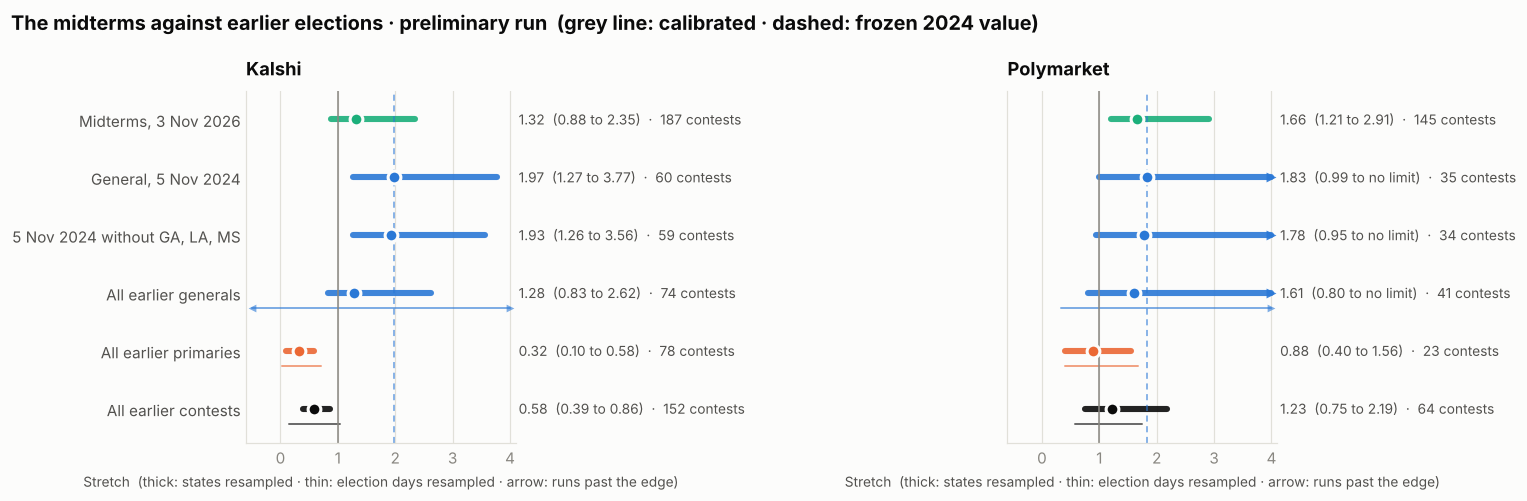

In [5]:
COLOUR = {"Midterms, 3 Nov 2026": MIDTERMS, "General, 5 Nov 2024": GENERAL, "5 Nov 2024 without GA, LA, MS": GENERAL,
          "All earlier generals": GENERAL, "All earlier primaries": PRIMARY, "All earlier contests": ALL}
LEFT, RIGHT = -0.5, 4.0
cut = lambda v: float(np.clip(v, LEFT, RIGHT))

def interval_bar(ax, low, high, y, colour, width, alpha):
    """A bar from low to high, with an arrow where it runs past the edge of the chart."""
    ax.plot([cut(low), cut(high)], [y, y], color=colour, linewidth=width, solid_capstyle="round", alpha=alpha)
    if low < LEFT:
        ax.scatter([LEFT], [y], marker="<", s=18 + 6 * width, color=colour, alpha=alpha, zorder=3, linewidth=0)
    if high > RIGHT:
        ax.scatter([RIGHT], [y], marker=">", s=18 + 6 * width, color=colour, alpha=alpha, zorder=3, linewidth=0)


fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
names = list(COLOUR)[::-1]
for ax, platform in zip(axes, PLATFORMS):
    part = fits[fits["platform"] == platform].set_index("group")
    for y, name in enumerate(names):
        row, colour = part.loc[name], COLOUR[name]
        interval_bar(ax, row["state_low"], row["state_high"], y, colour, 4, 0.9)
        if not np.isnan(row["day_low"]):
            interval_bar(ax, row["day_low"], row["day_high"], y - 0.26, colour, 1.3, 0.6)
        ax.scatter([cut(row["stretch"])], [y], s=70, color=colour, zorder=4, edgecolor=SURFACE, linewidth=2)
        ax.text(RIGHT + 0.15, y, f"{show(row['stretch'])}  ({span(row['state_low'], row['state_high'])})  ·  "
                f"{int(row['contests'])} contests", va="center", fontsize=9, color=INK_2)
    ax.axvline(1, color=MUTED, linewidth=1)
    ax.axvline(midterm_test.BASELINE_B[platform], color=GENERAL, linewidth=1, linestyle=(0, (4, 3)), alpha=0.7)
    ax.set_xlim(LEFT - 0.1, RIGHT + 0.1)
    ax.set_ylim(-0.6, len(names) - 0.5)
    ax.set_yticks(range(len(names)), names if ax is axes[0] else [""] * len(names))
    ax.set_xlabel("Stretch  (thick: states resampled · thin: election days resampled · arrow: runs past the edge)",
                  fontsize=9)
    ax.set_title(platform, pad=10)
    value_grid(ax, "x")
fig.suptitle(f"The midterms against earlier elections · {STAGE} run  "
             "(grey line: calibrated · dashed: frozen 2024 value)", x=0.01, ha="left", fontsize=13, weight="bold")
fig.tight_layout(w_pad=17)
save(fig, "stretch")

## 2. How often favourites won, by price

The three groups that don't overlap: the midterms, the 5 November 2024 night, and the earlier primaries. Contests are
grouped by the favourite's price. Each dot is the share of favourites that won in that price group, plotted at the
group's average price, with its 95% interval. The grey diagonal is a calibrated market; dots above it mean favourites
won more often than their price said. Each line is that group's fitted stretch. The table below gives the counts behind
every dot.

contests  favourites that won  \
platform   group                 price band                                  
Kalshi     Midterms, 3 Nov 2026  50%-60%           23                   13   
                                 60%-70%           23                   11   
                                 70%-80%           37                   29   
                                 80%-90%           52                   47   
                                 90%-95%           52                   52   
           General, 5 Nov 2024   50%-60%           13                    8   
                                 60%-70%           16                   10   
                                 70%-80%            8                    7   
                                 80%-90%           12                   12   
                                 90%-95%           11                   11   
           All earlier primaries 50%-60%            7                    3   
                                 60%-70%            5                    2   
                                 70%-80%           13                    7   
                                 80%-90%           27                   15   
                                 90%-95%           26                   20   
Polymarket Midterms, 3 Nov 2026  50%-60%           19                   11   
                                 60%-70%           14                    8   
                                 70%-80%           28                   23   
                                 80%-90%           39                   38   
                                 90%-95%           45                   45   
           General, 5 Nov 2024   50%-60%            4                    3   
                                 60%-70%            6                    6   
                                 70%-80%            5                    4   
                                 80%-90%           13                   12   
                                 90%-95%            7                    7   
           All earlier primaries 50%-60%            1                    0   
                                 60%-70%            2                    1   
                                 70%-80%            3                    0   
                                 80%-90%            9                    8   
                                 90%-95%            8                    8   

                                             share won  average price  
platform   group                 price band                            
Kalshi     Midterms, 3 Nov 2026  50%-60%         0.565          0.548  
                                 60%-70%         0.478          0.650  
                                 70%-80%         0.784          0.751  
                                 80%-90%         0.904          0.853  
                                 90%-95%         1.000          0.934  
           General, 5 Nov 2024   50%-60%         0.615          0.549  
                                 60%-70%         0.625          0.644  
                                 70%-80%         0.875          0.750  
                                 80%-90%         1.000          0.848  
                                 90%-95%         1.000          0.935  
           All earlier primaries 50%-60%         0.429          0.551  
                                 60%-70%         0.400          0.664  
                                 70%-80%         0.538          0.761  
                                 80%-90%         0.556          0.850  
                                 90%-95%         0.769          0.929  
Polymarket Midterms, 3 Nov 2026  50%-60%         0.579          0.553  
                                 60%-70%         0.571          0.650  
                                 70%-80%         0.821          0.755  
                                 80%-90%         0.974          0.858  
                                 90%

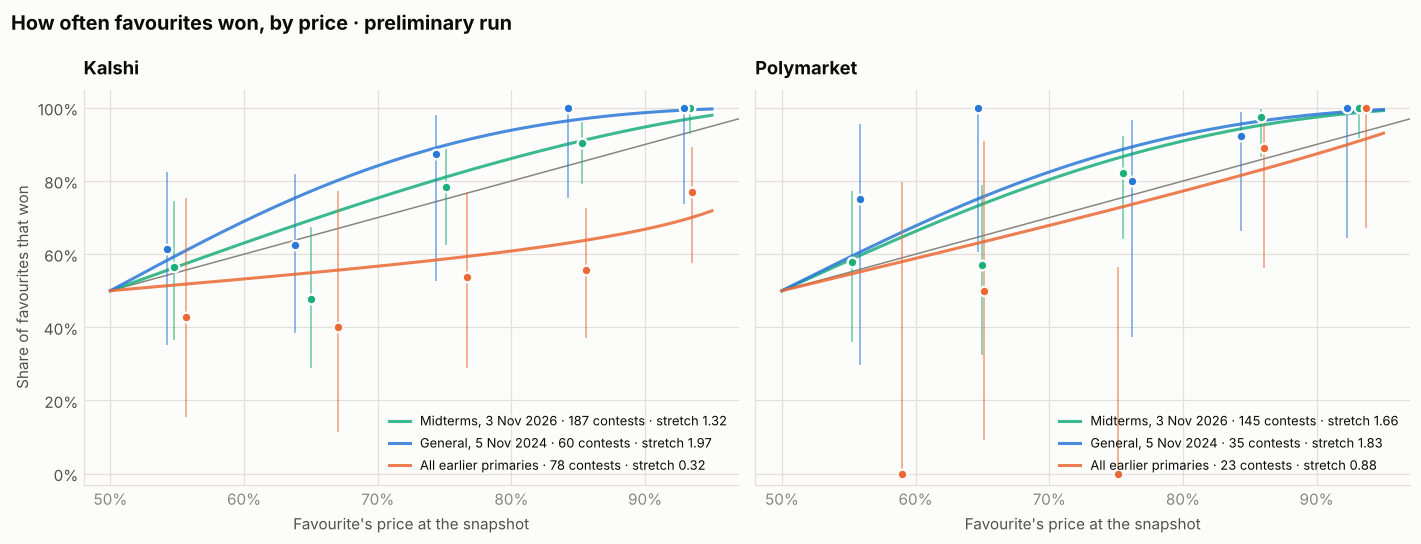

In [6]:
EDGES = [0.5, 0.6, 0.7, 0.8, 0.9, 0.951]
SHOWN = {"Midterms, 3 Nov 2026": MIDTERMS, "General, 5 Nov 2024": GENERAL, "All earlier primaries": PRIMARY}
OFFSET = {"Midterms, 3 Nov 2026": 0.0, "General, 5 Nov 2024": -0.006, "All earlier primaries": 0.006}
grid = np.linspace(0.5, 0.95, 200)

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
bin_rows = []
for ax, platform in zip(axes, PLATFORMS):
    ax.plot([0.5, 1], [0.5, 1], color=MUTED, linewidth=1)
    for name, colour in SHOWN.items():
        part = data[platform][name]
        b = stretch.fit(part["log_odds"], part["won"])
        ax.plot(grid, stretch.stretch(grid, np.clip(b, -50, 50)), color=colour, linewidth=2, alpha=0.85,
                label=f"{name} · {len(part)} contests · stretch {show(b)}")
        for band, group in part.groupby(pd.cut(part["price"], EDGES, include_lowest=True, right=False), observed=True):
            n, wins = len(group), int(group["won"].sum())
            low, high = stretch.wilson(wins, n)
            x = group["price"].mean() + OFFSET[name]
            ax.plot([x, x], [low, high], color=colour, linewidth=1.2, alpha=0.55)
            ax.scatter([x], [wins / n], s=40, color=colour, zorder=3, edgecolor=SURFACE, linewidth=1.5)
            bin_rows.append({"platform": platform, "group": name, "price band": f"{band.left:.0%}-{min(band.right, 0.95):.0%}",
                             "contests": n, "favourites that won": wins, "share won": wins / n,
                             "average price": group["price"].mean()})
    ax.set_xlim(0.48, 0.97)
    ax.set_ylim(-0.03, 1.05)
    ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.set_xlabel("Favourite's price at the snapshot")
    ax.set_title(platform, pad=10)
    value_grid(ax, "both")
    ax.legend(loc="lower right", fontsize=8.5, handlelength=1.6)
axes[0].set_ylabel("Share of favourites that won")
fig.suptitle(f"How often favourites won, by price · {STAGE} run", x=0.01, ha="left", fontsize=13, weight="bold")
fig.tight_layout()
save(fig, "calibration")

bins = pd.DataFrame(bin_rows)
bins.to_csv(RESULTS / f"{OUT}_price_bands.csv", index=False)
bins.round(3).set_index(["platform", "group", "price band"])

## 3. Every earlier election day

The midterms next to each earlier election day on its own. For each day: how many points more often favourites won than
their average price said (the gap), with a 95% interval. Days are coloured by kind: midterms aqua, general elections
blue, primaries orange. Only days with at least five contests are drawn, since smaller days say almost nothing alone; the
table lists every day. A single day rarely settles anything; the chart shows whether the midterms look like the
earlier nights.

kind  contests  states  \
platform   election day                                      
Kalshi     2024-11-05            General        60      29   
           2025-01-28            Primary         3       1   
           2025-04-01            General         1       1   
           2025-11-04            General         8       5   
           2025-12-02            General         1       1   
           2026-03-03            Primary        15       3   
           2026-03-10            Primary         1       1   
           2026-03-17            Primary         5       1   
           2026-03-24            General         2       1   
           2026-03-31            Primary         1       1   
           2026-05-05            Primary         2       1   
           2026-05-12            Primary         2       2   
           2026-05-19    General/Primary        12       4   
           2026-06-02            Primary         3       2   
           2026-06-09            Primary         1       1   
           2026-06-16            Primary         5       1   
           2026-06-23            Primary         7       4   
           2026-06-30            Primary         2       1   
           2026-07-21            Primary         2       1   
           2026-08-04            Primary         6       3   
           2026-08-11            Primary         4       2   
           2026-08-18            Primary         4       2   
           2026-08-25            Primary         2       1   
           2026-09-01            Primary         1       1   
           2026-09-09            Primary         1       1   
           2026-09-15            Primary         1       1   
           2026-11-03           Midterms       187      36   
Polymarket 2023-11-07            General         1       1   
           2024-02-13            General         1       1   
           2024-06-18            Primary         1       1   
           2024-08-13            Primary         1       1   
           2024-11-05            General        35      26   
           2025-04-01            General         1       1   
           2025-04-15            General         1       1   
           2025-11-04            General         1       1   
           2026-03-03            Primary         1       1   
           2026-05-26            Primary         1       1   
           2026-06-09            Primary         1       1   
           2026-06-16            Primary         1       1   
           2026-06-23            Primary         2       2   
           2026-06-30            Primary         1       1   
           2026-07-21            Primary         2       1   
           2026-08-04            Primary         1       1   
           2026-08-06            Primary         1       1   
           2026-08-11            Primary         2       1   
           2026-08-18    General/Primary         3       2   
           2026-08-25            Primary         2       1   
           2026-09-01            Primary         1       1   
           2026-09-09            Primary         2       1   
           2026-09-15            Primary         1       1   
           2026-11-03           Midterms       145      34   

                         favourite's average price  \
platform   election day                              
Kalshi     2024-11-05                        0.732   
           2025-01-28                        0.927   
           2025-04-01                        0.855   
           2025-11-04                        0.863   
           2025-12-02                        0.910   
           2026-03-03                        0.768   
           2026-03-10                        0.716   
           2026-03-17                        0.793   
           2026-03-24                        0.798   
           2026-03-31                        0.906   
           2026-05-05                        0.935   
           2026-05-12                        0.

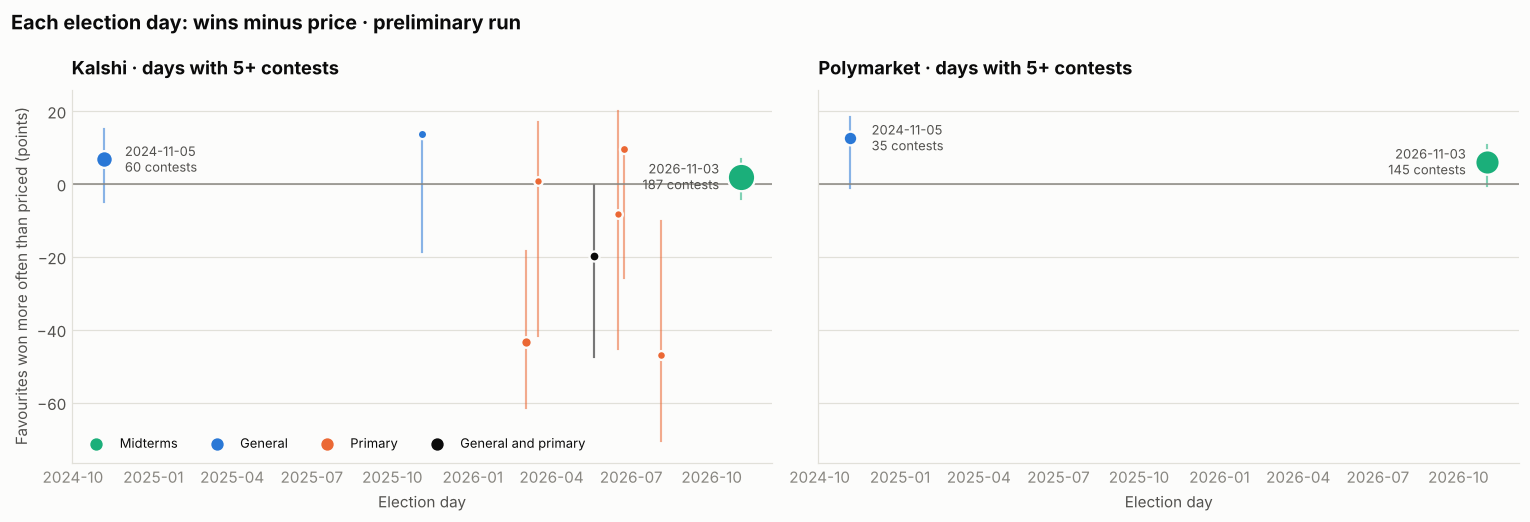

In [7]:
MIN_DAY = 5
day_rows = []
for platform in PLATFORMS:
    every = pd.concat([data[platform]["All earlier contests"], data[platform]["Midterms, 3 Nov 2026"]])
    for day, part in every.groupby("election_key"):
        n, wins = len(part), int(part["won"].sum())
        low, high = stretch.wilson(wins, n)
        kind = "Midterms" if day == midterm_test.TEST_DAY else "/".join(sorted(part["kind"].unique()))
        day_rows.append({"platform": platform, "election day": day.split("-", 1)[1], "kind": kind, "contests": n,
                         "states": part["state"].nunique(), "favourite's average price": part["price"].mean(),
                         "share of favourites that won": wins / n,
                         "gap, points": 100 * (wins / n - part["price"].mean()),
                         "gap low": 100 * (low - part["price"].mean()), "gap high": 100 * (high - part["price"].mean()),
                         "upsets expected": (1 - part["price"]).sum(), "upsets": n - wins,
                         "stretch": stretch.fit(part["log_odds"], part["won"])})
days = pd.DataFrame(day_rows)
days.to_csv(RESULTS / f"{OUT}_election_days.csv", index=False)

KIND_COLOUR = {"Midterms": MIDTERMS, "General": GENERAL, "Primary": PRIMARY, "General/Primary": ALL}
big = days[days["contests"] >= MIN_DAY]
low_y, high_y = big["gap low"].min() - 6, big["gap high"].max() + 6
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
for ax, platform in zip(axes, PLATFORMS):
    shown = days[(days["platform"] == platform) & (days["contests"] >= MIN_DAY)].copy()
    shown["date"] = pd.to_datetime(shown["election day"])
    for _, row in shown.iterrows():
        colour = KIND_COLOUR.get(row["kind"], ALL)
        ax.plot([row["date"]] * 2, [row["gap low"], row["gap high"]], color=colour, linewidth=1.4, alpha=0.55)
        ax.scatter([row["date"]], [row["gap, points"]], s=24 + 1.6 * row["contests"], color=colour, zorder=3,
                   edgecolor=SURFACE, linewidth=1.5)
        if row["kind"] == "Midterms" or row["contests"] >= 30:
            last = row["kind"] == "Midterms"
            ax.annotate(f"{row['election day']}\n{row['contests']} contests", (row["date"], row["gap, points"]),
                        xytext=(-14 if last else 14, 0), textcoords="offset points", ha="right" if last else "left",
                        va="center", fontsize=8.5, color=INK_2)
    ax.axhline(0, color=MUTED, linewidth=1)
    ax.set_ylim(low_y, high_y)
    ax.set_title(f"{platform} · days with {MIN_DAY}+ contests", pad=10)
    ax.set_xlabel("Election day")
    value_grid(ax, "y")
for kind, colour in KIND_COLOUR.items():
    axes[0].scatter([], [], s=50, color=colour, label={"General/Primary": "General and primary"}.get(kind, kind))
axes[0].legend(loc="lower left", fontsize=8.5, ncol=4)
axes[0].set_ylabel("Favourites won more often than priced (points)")
fig.suptitle(f"Each election day: wins minus price · {STAGE} run", x=0.01, ha="left", fontsize=13, weight="bold")
fig.tight_layout()
save(fig, "election_days")

days.round(3).set_index(["platform", "election day"])

## 4. Would the earlier elections have improved the midterm prices?

This is the out-of-sample version of the question. Each midterm price is stretched with a value fixed before the vote,
and the result is scored against what happened. **Log loss** is the average penalty for the chance a forecast gave to
what actually happened; lower is better. **Improvement** is the raw prices' log loss minus the stretched prices', so above
0 means the stretch helped. Its interval resamples the midterms' states, with the stretch value held fixed.

The values tried:
- the frozen 2024 value;
- every earlier general election;
- every earlier primary;
- every earlier contest.

The last row stretches by the midterms' own value. It is fitted to the same contests it is scored on, so it is the best
any single stretch could have done here: a ceiling, not a forecast.

stretch  log loss, raw  \
platform   stretch from                                            
Kalshi     Frozen 2024 value               1.9716         0.3861   
           All earlier generals            1.2773         0.3861   
           All earlier primaries           0.3185         0.3861   
           All earlier contests            0.5797         0.3861   
           Midterms' own value (ceiling)   1.3193         0.3861   
Polymarket Frozen 2024 value               1.8278         0.3249   
           All earlier generals            1.6077         0.3249   
           All earlier primaries           0.8816         0.3249   
           All earlier contests            1.2281         0.3249   
           Midterms' own value (ceiling)   1.6642         0.3249   

                                          log loss, stretched  improvement  \
platform   stretch from                                                      
Kalshi     Frozen 2024 value                           0.4027      -0.0166   
           All earlier generals                        0.3758       0.0103   
           All earlier primaries                       0.5293      -0.1432   
           All earlier contests                        0.4475      -0.0614   
           Midterms' own value (ceiling)               0.3757       0.0104   
Polymarket Frozen 2024 value                           0.2933       0.0317   
           All earlier generals                        0.2922       0.0328   
           All earlier primaries                       0.3413      -0.0164   
           All earlier contests                        0.3043       0.0206   
           Midterms' own value (ceiling)               0.2920       0.0329   

                                             low    high  Brier, raw  \
platform   stretch from                                                
Kalshi     Frozen 2024 value             -0.1239  0.0724      0.1231   
           All earlier generals          -0.0201  0.0359      0.1231   
           All earlier primaries         -0.2111 -0.0673      0.1231   
           All earlier contests          -0.1020 -0.0143      0.1231   
           Midterms' own value (ceiling) -0.0246  0.0400      0.1231   
Polymarket Frozen 2024 value             -0.0268  0.0807      0.0974   
           All earlier generals          -0.0104  0.0691      0.0974   
           All earlier primaries         -0.0237 -0.0076      0.0974   
           All earlier contests           0.0042  0.0344      0.0974   
           Midterms' own value (ceiling) -0.0142  0.0725      0.0974   

                                          Brier, stretched  
platform   stretch from                                     
Kalshi     Frozen 2024 value                        0.1321  
           All earlier generals                     0.1231  
           All earlier primaries                    0.1712  
           All earlier contests                     0.1389  
           Midterms' own value (ceiling)            0.1235  
Polymarket Frozen 2024 value                        0.0952  
           All earlier generals                     0.0939  
           All earlier primaries                    0.1010  
           All earlier contests                     0.0941  
           Midterms' own value (ceiling)            0.0942

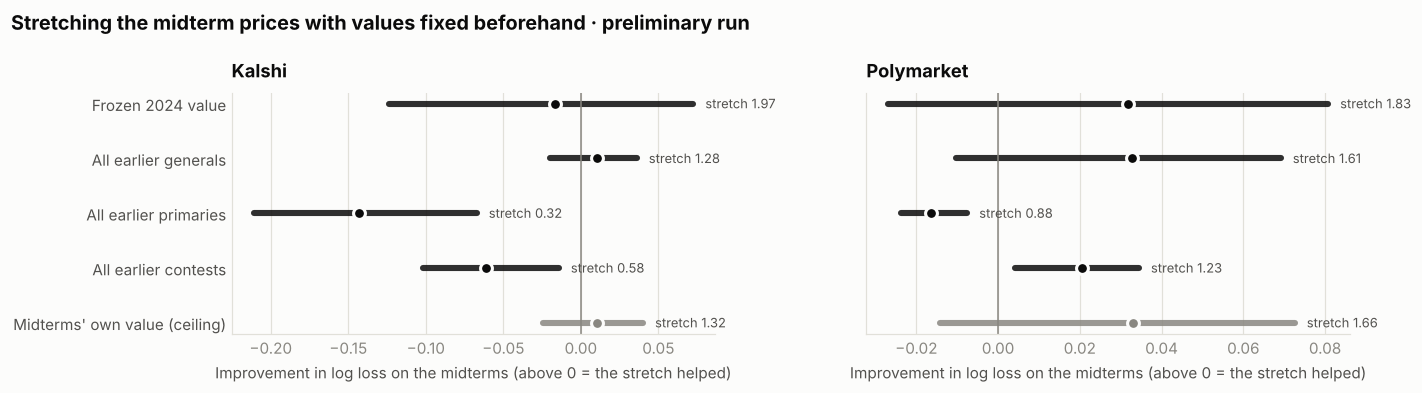

In [8]:
def log_losses(price, won, b):
    chance = stretch.stretch(price, b)
    return -np.log(np.where(won == 1, chance, 1 - chance))


rng = np.random.default_rng(stretch.SEED)
score_rows = []
for platform in PLATFORMS:
    test = data[platform]["Midterms, 3 Nov 2026"]
    price, won = test["price"].to_numpy(), test["won"].to_numpy()
    raw = log_losses(price, won, 1.0)
    states = test["state"].to_numpy()
    rows_of = [np.flatnonzero(states == s) for s in np.unique(states)]
    draws = [np.concatenate([rows_of[j] for j in rng.integers(0, len(rows_of), len(rows_of))])
             for _ in range(stretch.RESAMPLES)]
    values = {"Frozen 2024 value": midterm_test.BASELINE_B[platform]}
    for name in ("All earlier generals", "All earlier primaries", "All earlier contests"):
        part = data[platform][name]
        values[name] = stretch.fit(part["log_odds"], part["won"])
    values["Midterms' own value (ceiling)"] = stretch.fit(test["log_odds"], test["won"])
    for name, b in values.items():
        stretched = log_losses(price, won, b)
        gain = raw - stretched
        boot = np.array([gain[rows].mean() for rows in draws])
        chance = stretch.stretch(price, b)
        score_rows.append({"platform": platform, "stretch from": name, "stretch": b,
                           "log loss, raw": raw.mean(), "log loss, stretched": stretched.mean(),
                           "improvement": gain.mean(), "low": np.quantile(boot, 0.025), "high": np.quantile(boot, 0.975),
                           "Brier, raw": stretch.brier(price, won), "Brier, stretched": stretch.brier(chance, won)})
scores = pd.DataFrame(score_rows)
scores.to_csv(RESULTS / f"{OUT}_scores.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.6), sharey=True)
order = list(values)[::-1]
for ax, platform in zip(axes, PLATFORMS):
    part = scores[scores["platform"] == platform].set_index("stretch from")
    for y, name in enumerate(order):
        row = part.loc[name]
        colour = MUTED if "ceiling" in name else ALL
        ax.plot([row["low"], row["high"]], [y, y], color=colour, linewidth=4, solid_capstyle="round", alpha=0.85)
        ax.scatter([row["improvement"]], [y], s=60, color=colour, zorder=3, edgecolor=SURFACE, linewidth=2)
        ax.annotate(f"stretch {row['stretch']:.2f}", (row["high"], y), xytext=(8, 0), textcoords="offset points",
                    va="center", fontsize=8.5, color=INK_2)
    ax.axvline(0, color=MUTED, linewidth=1)
    ax.set_yticks(range(len(order)), order)
    ax.set_xlabel("Improvement in log loss on the midterms (above 0 = the stretch helped)")
    ax.set_title(platform, pad=10)
    value_grid(ax, "x")
fig.suptitle(f"Stretching the midterm prices with values fixed beforehand · {STAGE} run", x=0.01, ha="left",
             fontsize=13, weight="bold")
fig.tight_layout(w_pad=6)
save(fig, "scores")

scores.round(4).set_index(["platform", "stretch from"])

## 5. The same midterm races on both platforms

The two platforms didn't list the same races. Kalshi, for example, also listed state judicial and other down-ballot
races. Part of any difference between their stretches could be which races each one had, not how each one priced
them. Here only races that both platforms listed and that passed every rule on both are kept, and the stretch is fitted
again on that shared set. The chart compares the chance each platform gave the candidate who actually won: a dot above
the diagonal means Polymarket gave the winner more.

141 races on both platforms (Kalshi listed 187, Polymarket 145); the two had the same favourite in 100% of them; average gap between their chances for the winner 0.9 points


,races,states,stretch,state_low,state_high,average chance for the winner,upsets expected,upsets
platform,,,,,,,,
Kalshi,141,34,1.680,1.210,3.002,0.755,28.871,20
Polymarket,141,34,1.648,1.182,2.886,0.757,28.426,20


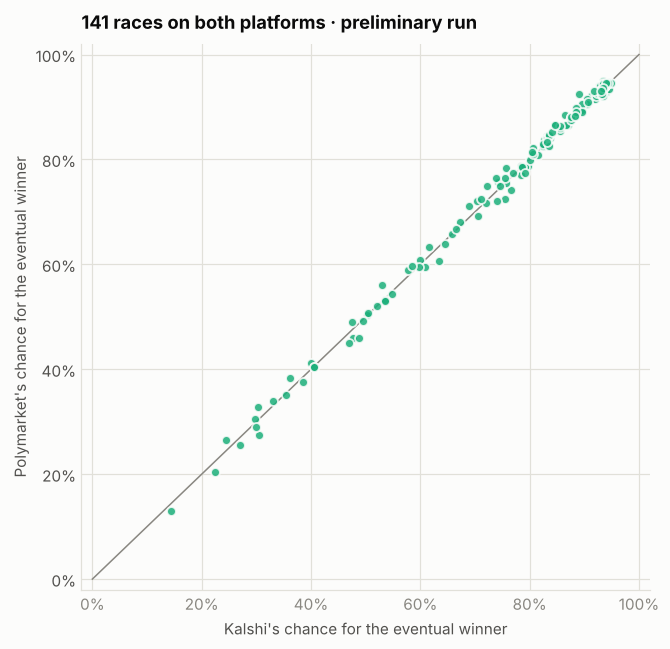

In [9]:
listed = pd.read_csv(midterm_test.ELIGIBLE, dtype={"contest_id": str})[["platform", "contest_id", "race"]]
sides = {}
for platform in PLATFORMS:
    test = data[platform]["Midterms, 3 Nov 2026"].merge(listed, on=["platform", "contest_id"], how="left")
    assert test["race"].notna().all()
    test["winner_chance"] = np.where(test["won"] == 1, test["price"], 1 - test["price"])
    sides[platform] = test
both = sides["Kalshi"].merge(sides["Polymarket"], on="race", suffixes=("_k", "_p"))
same_favourite = (both["won_k"] == both["won_p"]).mean()  # same winner, so same result means same favourite
print(f"{len(both)} races on both platforms (Kalshi listed {len(sides['Kalshi'])}, Polymarket {len(sides['Polymarket'])}); "
      f"the two had the same favourite in {same_favourite:.0%} of them; "
      f"average gap between their chances for the winner {100 * (both['winner_chance_p'] - both['winner_chance_k']).abs().mean():.1f} points")

shared_rows = []
for platform, suffix in (("Kalshi", "_k"), ("Polymarket", "_p")):
    part = sides[platform][sides[platform]["race"].isin(both["race"])].reset_index(drop=True)
    low, high = stretch.interval(stretch.bootstrap(part, "state")["All"])
    shared_rows.append({"platform": platform, "races": len(part), "states": part["state"].nunique(),
                        "stretch": stretch.fit(part["log_odds"], part["won"]), "state_low": low, "state_high": high,
                        "average chance for the winner": part["winner_chance"].mean(),
                        "upsets expected": (1 - part["price"]).sum(), "upsets": int((1 - part["won"]).sum())})
shared = pd.DataFrame(shared_rows)
shared.to_csv(RESULTS / f"{OUT}_same_races.csv", index=False)

fig, ax = plt.subplots(figsize=(6.2, 6))
ax.plot([0, 1], [0, 1], color=MUTED, linewidth=1)
ax.scatter(both["winner_chance_k"], both["winner_chance_p"], s=34, color=MIDTERMS, alpha=0.85, edgecolor=SURFACE,
           linewidth=1.2, zorder=3)
ax.set_xlim(-0.02, 1.02)
ax.set_ylim(-0.02, 1.02)
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_xlabel("Kalshi's chance for the eventual winner")
ax.set_ylabel("Polymarket's chance for the eventual winner")
ax.set_title(f"{len(both)} races on both platforms · {STAGE} run", pad=10)
value_grid(ax, "both")
fig.tight_layout()
save(fig, "same_races")

shared.round(3).set_index("platform")

## Files

Everything above is saved for the write-up:
- `results/midterm_comparison_<stage>_groups.csv`
- `results/midterm_comparison_<stage>_price_bands.csv`
- `results/midterm_comparison_<stage>_election_days.csv`
- `results/midterm_comparison_<stage>_scores.csv`
- `results/midterm_comparison_<stage>_same_races.csv`
- figures `figures/midterm_comparison_<stage>_{stretch, calibration, election_days, scores, same_races}` as PNG and PDF

After the final run in January, run this notebook again: it picks up `midterm_test_final.csv` by itself and writes a
`final` set alongside the preliminary one.